<a href="https://colab.research.google.com/github/kumarmaheshbly-oss/Project-Aura-/blob/main/network_aware_collision_avoidance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🚨 Original Distance to Debris: 2.24 units
--------------------------------------------------
🛑 BLIND DODGE (Standard Industry Approach):
New Position: [-2.68328157 -1.34164079]
Distance to Neighbor: 12.75 units
❌ ALERT: Optical Link BROKEN due to maneuver!
--------------------------------------------------
🧠 SMART DODGE (Project Aura NA-CAM):
New Position: [-0.51402352  2.95563526]
Distance to Neighbor: 10.92 units
✅ SUCCESS: Collision Avoided AND Network Link Maintained!


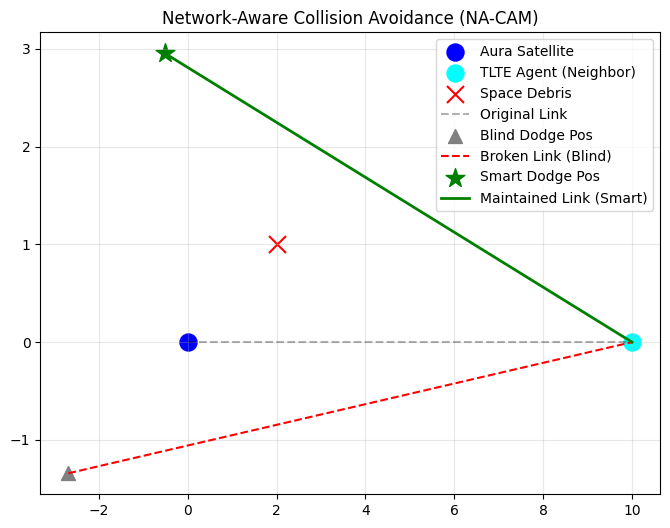

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Setup positions (2D plane mein demo)
# Satellite A (jo bachega)
sat_A = np.array([0.0, 0.0])
# Satellite B (jiske saath link maintain rakhna hai)
sat_B = np.array([10.0, 0.0])
# Space Debris (jo takrav karne aa raha hai)
debris = np.array([2.0, 1.0])

# 2. Normal Collision Avoidance (Blind Dodge)
# Sabse basic tarika: Debris ke ulte direction mein bhag jao
blind_dodge_vector = sat_A - debris
blind_dodge_vector = blind_dodge_vector / np.linalg.norm(blind_dodge_vector) * 3.0 # 3 units door bhag
new_pos_blind = sat_A + blind_dodge_vector

# Check karein ki link tooti ya nahi
link_dist_blind = np.linalg.norm(new_pos_blind - sat_B)

# 3. Network-Aware Collision Avoidance (The Unthought Way)
# Humein aise bachna hai ki Sat_B se distance kam se kam 8 units rahe.
# Hum ek perpendicular vector nikalenge jo link ko break na kare.
link_vector = sat_B - sat_A
# Perpendicular vector (90 degree angle) nikalein
perp_vector = np.array([-link_vector[1], link_vector[0]])
perp_vector = perp_vector / np.linalg.norm(perp_vector)

# Hum perpendicular direction mein thoda move karenge taaki debris se bachein
# Par link ke direction mein nahi (taaki link intact rahe)
smart_dodge_vector = perp_vector * 2.5 + (sat_A - debris) * 0.2
smart_dodge_vector = smart_dodge_vector / np.linalg.norm(smart_dodge_vector) * 3.0
new_pos_smart = sat_A + smart_dodge_vector

# Check karein ki link tooti ya nahi
link_dist_smart = np.linalg.norm(new_pos_smart - sat_B)

# 4. Print Analysis
print(f"🚨 Original Distance to Debris: {np.linalg.norm(sat_A - debris):.2f} units")
print("--------------------------------------------------")
print("🛑 BLIND DODGE (Standard Industry Approach):")
print(f"New Position: {new_pos_blind}")
print(f"Distance to Neighbor: {link_dist_blind:.2f} units")
if link_dist_blind > 12:
    print("❌ ALERT: Optical Link BROKEN due to maneuver!")

print("--------------------------------------------------")
print("🧠 SMART DODGE (Project Aura NA-CAM):")
print(f"New Position: {new_pos_smart}")
print(f"Distance to Neighbor: {link_dist_smart:.2f} units")
if link_dist_smart < 12:
    print("✅ SUCCESS: Collision Avoided AND Network Link Maintained!")

# 5. Plotting (For Meeting Visuals)
plt.figure(figsize=(8, 6))
plt.scatter(*sat_A, color='blue', s=150, label='Aura Satellite')
plt.scatter(*sat_B, color='cyan', s=150, label='TLTE Agent (Neighbor)')
plt.scatter(*debris, color='red', marker='x', s=150, label='Space Debris')

# Original Link
plt.plot([sat_A[0], sat_B[0]], [sat_A[1], sat_B[1]], 'k--', alpha=0.3, label='Original Link')

# Blind Dodge
plt.scatter(*new_pos_blind, color='gray', marker='^', s=100, label='Blind Dodge Pos')
plt.plot([new_pos_blind[0], sat_B[0]], [new_pos_blind[1], sat_B[1]], 'r--', label='Broken Link (Blind)')

# Smart Dodge
plt.scatter(*new_pos_smart, color='green', marker='*', s=200, label='Smart Dodge Pos')
plt.plot([new_pos_smart[0], sat_B[0]], [new_pos_smart[1], sat_B[1]], 'g-', linewidth=2, label='Maintained Link (Smart)')

plt.legend()
plt.title("Network-Aware Collision Avoidance (NA-CAM)")
plt.grid(True, alpha=0.3)
plt.show()